# 4. Space-charge prefill test — Python

Build the fixed upstream prefill field `Esz00`, using the existing `SpaceChargeState` plasma-frequency and prefill methods. This corresponds to `KLJCmainsv22.m` lines 151–179, after the reference beam, grid and charge harmonics have been initialized.

1. Edit the inputs and **Restart Kernel and Run All** here.
2. Run `spacecharge_prefill_test.mlx` (or the readable `.m` source).
3. Run `compare_results.ipynb`.

The auxiliary upstream source grid does **not** enlarge the solver grid. `QQfill` lives on `zp`; its field `Esz00` is evaluated on the normal `z` grid. No in-domain space-charge update, RF field, trajectory or nonlinear iteration is run.


In [1]:
# Import necessary libraries and modules

from pathlib import Path
import sys

import numpy as np
import matplotlib.pyplot as plt
from scipy.io import savemat
from IPython.display import Markdown, display


In [2]:
# Import custom modules and classes to be tested

current_directory = Path.cwd().resolve()
project_directory = next(
    path
    for parent in (current_directory, *current_directory.parents)
    for path in (parent, parent / "pyKlyC")
    if (path / "src" / "solver" / "grid.py").exists()
)
test_directory = project_directory / "test" / "4.spacecharge_prefll_test"
sys.path.insert(0, str(project_directory / "src"))

from constants import c, etom, mu01
from model.beam import BeamParameters
from model.cavity import CavityParameters
from model.settings import NumericalSettings
from model.tube import TubeParameters
from solver.reference import ReferenceParameters
from solver.grid import GridParameters
from solver.beam_state import BeamState

from solver.space_charge import SpaceChargeState


In [3]:
# Set global options for numpy and matplotlib

np.set_printoptions(precision=6, linewidth=140)
# Apply the same dashed gray grid to every subplot.
# "line" places the grid above shaded regions, but below plotted lines.
plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 10,
    "axes.grid": True,
    "axes.axisbelow": "line",
    "grid.color": "gray",
    "grid.linestyle": "--",
    "grid.linewidth": 0.7,
    "grid.alpha": 0.45,
})

# Display options for Jupyter Notebook Tables

def show_table(rows):
    text = "| Variable | Value | Units | Meaning |\n"
    text += "|---|---|---|---|\n"
    for name, value, units, meaning in rows:
        if isinstance(value, np.ndarray):
            value = np.array2string(value, precision=5, max_line_width=1000)
        elif isinstance(value, (float, np.floating)):
            value = f"{value:.8g}"
        text += f"| `{name}` | {value} | {units} | {meaning} |\n"
    display(Markdown(text))


## 1. Editable inputs

The same beam presets as test 3 are available: `uniform` (default), `modulated`, and `partial_beam`. Use `modulated` to see nonzero RF prefill harmonics. These are prescribed entrance conditions, not propagated beam solutions.

Space-charge controls:

- `factor` multiplies the plasma frequency `wp`; the prefill field therefore scales as `factor**2`.
- `factorregion` sets the upstream range through `dN = floor(factorregion*rc/(2.40483*dz))`.
- `fillfactor` and `DCSPfactor` are **nonzero gates at this stage**, not multipliers in `Esz00`. Setting either to zero disables the prefill field. Their later weighting of the total field is outside this test.
- Setting `factorregion=0` gives an empty upstream source grid and a zero field.

Lengths are in mm, input frequencies in GHz, voltages in kV, and currents in A. This test covers a cylindrical solid or annular electron beam, with a constant tunnel radius.

**Known original MATLAB edge case:** with enabled prefill and exactly one source (`dN=1`), its unqualified `sum(...)` reduces across harmonics rather than sources. Python explicitly sums source rows. This case is expected to fail MATLAB consistency checks or comparison; it is not corrected or hidden here. With the supplied modulated preset, `factorregion=0.2` reproduces it. The default `factorregion=10` gives 52 sources and passes. See the test README.


In [4]:
case_name = "uniform"  # "uniform", "modulated", or "partial_beam"

# Beam and emission samples
Nbeam = 1
rm1 = 0.0
rm2 = 6.0
rc = 10.0
Nt = 128
t0 = 2.0 * np.pi * np.arange(Nt) / Nt
tn1 = t0.copy()
Y0 = np.arange(Nt)
Ut = np.full(Nt, 180.0)
Izt = np.full(Nt, -16.0)

# Prescribed test inputs: no electron trajectories are calculated.
if case_name in ("modulated", "partial_beam"):
    Izt = -16.0 * (1.0 + 0.20 * np.cos(t0 + 0.40) + 0.10 * np.sin(2.0 * t0 - 0.20))
    Ut = 180.0 * (1.0 + 0.03 * np.sin(t0 - 0.30))
    tn1 = t0 + 0.35
    if case_name == "partial_beam":
        Y0 = np.flatnonzero(t0 < np.pi)
elif case_name != "uniform":
    raise ValueError("Choose uniform, modulated, or partial_beam.")

# Cavity centers and RF parameters (no RF fields are calculated)
Nc = 5
f = 1.0
f0 = np.array([1.000, 1.006, 1.016, 1.030, 1.000])
zshift = np.array([0.0, 480.0, 1630.0, 2400.0, 2730.0])
type = np.array([0, 1, 1, 1, -1])
nh = np.ones(Nc, dtype=int)
Qext = np.array([334.0, 95000.0, 95000.0, 95000.0, 50.0])
Qin = np.array([16428.0, 19768.0, 19816.0, 16970.0, 14787.0])
Pin = np.array([60.0, 0.0, 0.0, 0.0, 0.0])
gaman = np.zeros(Nc, dtype=complex)
Lsb = np.pi * np.ones(Nc)
kai = np.zeros((Nc, Nc), dtype=complex)
cavityname = " ".join(f"guide_cavity_{k + 1}" for k in range(Nc))

# Longitudinal domain and constant-radius tunnel
z0 = -100.0
L = 3000.0
rcv = np.array([
    [z0, z0 + L],
    [1.0, 1.0],
])

# Numerical parameters
Nz = 256
Ns = 8
factorregion = 10.0
Nlimit = 100
Ntimes = 10
Rlimit = 1.0e-4
iterfactor = 0.5

# Prefill controls (the later SpaceChargeState.update() is not called)
factor = 1.0
fillfactor = 1.0
DCSPfactor = 1.0


## 2. Initialize the reference beam, grid and charge harmonics

These quantities are recalculated from raw inputs. No results from tests 1–3 are imported. The cavity settings are required by the grid API; no cavity fields are generated.


In [5]:
beam = BeamParameters(
    Nbeam=Nbeam, rm1=rm1, rm2=rm2, rc=rc,
    xb=0.0, yb=0.0, xd=0.0, yd=0.0,
    Nt=Nt, t0=t0, Ut=Ut, Izt=Izt, tn1=tn1, Y0=Y0,
)
cavities = CavityParameters(
    type=type, nh=nh, f0=f0, Qext=Qext, Qin=Qin,
    zshift=zshift, Pin=Pin, gaman=gaman, Lsb=Lsb,
    cavityname=cavityname, kai=kai,
)
tube = TubeParameters(z0=z0, L=L, rcv=rcv)
numerical = NumericalSettings(
    f=f, Nc=Nc, Ns=Ns, Nz=Nz, Nlimit=Nlimit,
    Ntimes=Ntimes, Rlimit=Rlimit, iterfactor=iterfactor,
    evolutionmethod=np.array([0.005, 2.0]),
)

cavities.validate(Nc)

reference = ReferenceParameters.calculate_reference_parameters(beam)
grid = GridParameters.calculate(
    numerical, cavities, tube, beam, reference, factorregion
)

beam_state = BeamState.initialize(numerical, beam, grid, reference)


## 3. Calculate the plasma frequency and prefill field

Only the two relevant existing methods are called, rather than initializing the unrelated later-update buffers. `wp` is in rad/s; `Esz00` is a **dimensionless solver field**, not V/m.

Arrays `zp`, `gamazp` and `QQfill` have shape `(Nfill, Ns+1)`; `Esz00` has shape `(len(z), Ns+1)`. Column zero is DC; the remaining columns are harmonics 1 through `Ns`.

Python retains the auxiliary source arrays even when prefill is disabled. The original MATLAB guard skips their creation in that case. The companion MATLAB test explicitly builds those arrays as **diagnostics only** when disabled, using the original formulas; the original zero-field behavior remains unchanged.


In [6]:
assert Nt >= 16 and 1 <= Ns < Nt / 2
assert 0 <= beam.rm1 < beam.rm2 <= beam.rc and beam.yd == 0.0
assert factor >= 0 and factorregion >= 0 and fillfactor >= 0 and DCSPfactor >= 0
np.testing.assert_allclose(grid.rcvs, beam.rc, rtol=0.0, atol=1e-12)

wp = SpaceChargeState.calculate_plasma_frequency(beam, reference, factor)
Esz00, zp, gamazp, QQfill = SpaceChargeState.calculate_prefill_space_charge(
    beam, grid, reference, beam_state, wp, fillfactor, DCSPfactor
)
Nfill = len(zp)
zp_mm = zp[:, 0] / grid.betae
harmonics = np.arange(Ns + 1)
prefill_enabled = factor != 0 and fillfactor != 0 and DCSPfactor != 0

show_table([
    ("case_name", case_name, "-", "Prescribed entrance-beam case"),
    ("I0", reference.I0, "A", "Magnitude of the mean current"),
    ("U0", reference.U0, "kV", "Current-weighted reference voltage"),
    ("s", reference.s, "1", "Reference speed divided by c"),
    ("wp", wp, "rad/s", "Plasma angular frequency including factor"),
    ("wp / (2*pi)", wp / (2*np.pi), "Hz", "Plasma frequency"),
    ("wp / w", wp / grid.w, "1", "Plasma-to-operating frequency ratio"),
    ("factor", factor, "1", "Multiplier of wp, not of wp squared"),
    ("fillfactor", fillfactor, "1", "Prefill gate here; weighting happens later"),
    ("DCSPfactor", DCSPfactor, "1", "Gate for the whole prefill calculation here"),
    ("dN = Nfill", Nfill, "sources", "Upstream nodes per harmonic"),
    ("dN*dz", Nfill * grid.dz, "mm", "Actual upstream extent"),
    ("dz", grid.dz, "mm", "Physical source and solver spacing"),
    ("dt", grid.dt, "1", "Normalized spacing: betae*dz"),
    ("QQfill.shape", str(QQfill.shape), "-", "Upstream sources x harmonics including DC"),
    ("Esz00.shape", str(Esz00.shape), "-", "Solver targets x harmonics including DC"),
])
print("Prefill enabled:", prefill_enabled)


| Variable | Value | Units | Meaning |
|---|---|---|---|
| `case_name` | uniform | - | Prescribed entrance-beam case |
| `I0` | 16 | A | Magnitude of the mean current |
| `U0` | 180 | kV | Current-weighted reference voltage |
| `s` | 0.67314584 | 1 | Reference speed divided by c |
| `wp` | 3.7316657e+09 | rad/s | Plasma angular frequency including factor |
| `wp / (2*pi)` | 5.9391305e+08 | Hz | Plasma frequency |
| `wp / w` | 0.59391305 | 1 | Plasma-to-operating frequency ratio |
| `factor` | 1 | 1 | Multiplier of wp, not of wp squared |
| `fillfactor` | 1 | 1 | Prefill gate here; weighting happens later |
| `DCSPfactor` | 1 | 1 | Gate for the whole prefill calculation here |
| `dN = Nfill` | 52 | sources | Upstream nodes per harmonic |
| `dN*dz` | 40.998686 | mm | Actual upstream extent |
| `dz` | 0.78843627 | mm | Physical source and solver spacing |
| `dt` | 0.024548027 | 1 | Normalized spacing: betae*dz |
| `QQfill.shape` | (52, 9) | - | Upstream sources x harmonics including DC |
| `Esz00.shape` | (3806, 9) | - | Solver targets x harmonics including DC |


Prefill enabled: True


## 4. Normal grid and upstream source grid

\[
zp_{j,k}=z(0)-j\,dt,\quad j=1,\ldots,dN,\qquad zp_{\mathrm{mm}}=zp/\beta_e.
\]

Every harmonic uses the same source positions. Stored rows run from the **nearest** upstream source to the **farthest**. The first source is one `dz` before the entrance; there is no duplicate source at the entrance.

The upper panel shows the entire domain. The lower panel zooms around the entrance, where the prefill field is appreciable. Both horizontal axes use physical millimetres.


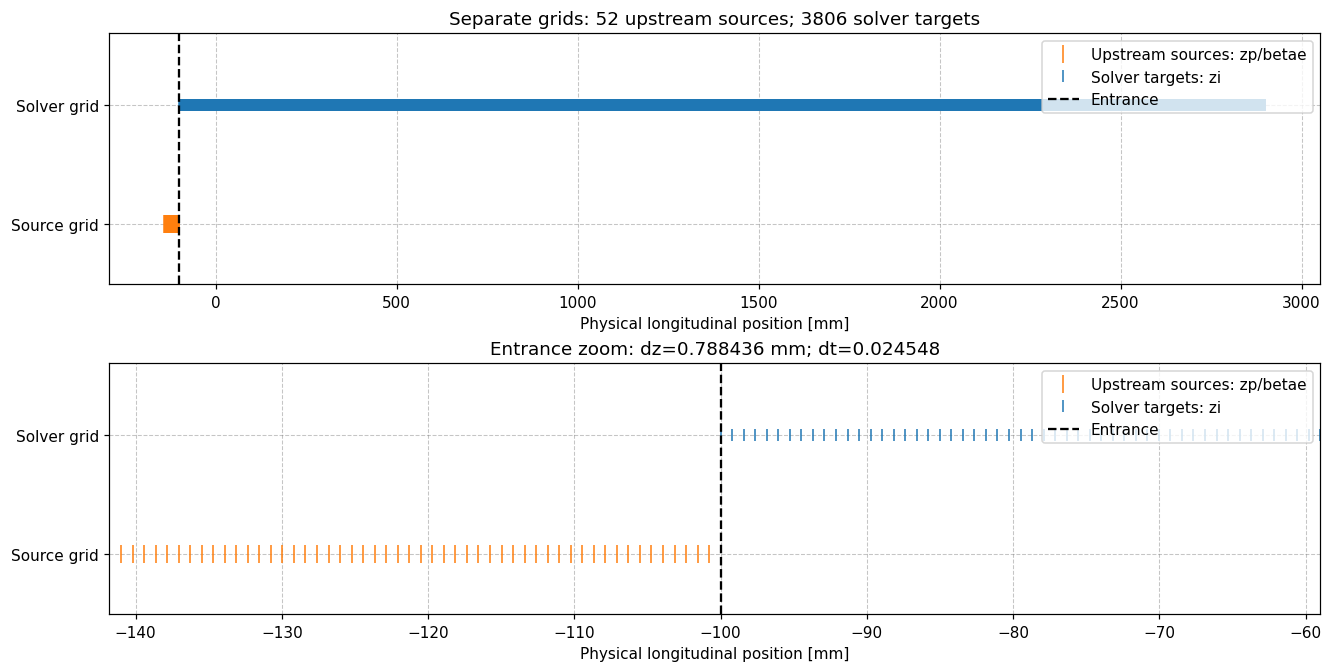

In [7]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6), layout="constrained")
for ax in axes:
    ax.plot(zp_mm, np.zeros(Nfill), "|", markersize=12, color="tab:orange", label="Upstream sources: zp/betae")
    ax.plot(grid.zi, np.ones(len(grid.zi)), "|", markersize=8, color="tab:blue", label="Solver targets: zi")
    ax.axvline(grid.zi[0], color="black", linestyle="--", label="Entrance")
    ax.set(yticks=[0, 1], yticklabels=["Source grid", "Solver grid"],
           ylim=(-0.5, 1.6), xlabel="Physical longitudinal position [mm]")
    ax.legend(loc="upper right")
axes[0].set_title(f"Separate grids: {Nfill} upstream sources; {len(grid.zi)} solver targets")
zoom_length = max(Nfill * grid.dz, 4.0 * beam.rc)
axes[1].set_xlim(grid.zi[0] - zoom_length - grid.dz, min(grid.zi[-1], grid.zi[0] + zoom_length))
axes[1].set_title(f"Entrance zoom: dz={grid.dz:.6g} mm; dt={grid.dt:.6g}")
plt.show()


## 5. Upstream charge and kernel factors

\[
QQfill_{j,0}=QQDC(0),\qquad
QQfill_{j,k}=QQ_k(0)e^{-ik[z(0)-zp_j]}.
\]

Only the RF columns rotate in phase upstream. Their magnitudes remain equal to the entrance magnitudes. `gamazp[:,0]=1` for DC, while the RF columns use `gamaz(0)`; the DC kernel is **not** multiplied by the beam Lorentz factor.

All source coefficients and kernel factors below are dimensionless. If a gate is zero, these are diagnostic sources only: they do not contribute to `Esz00`.


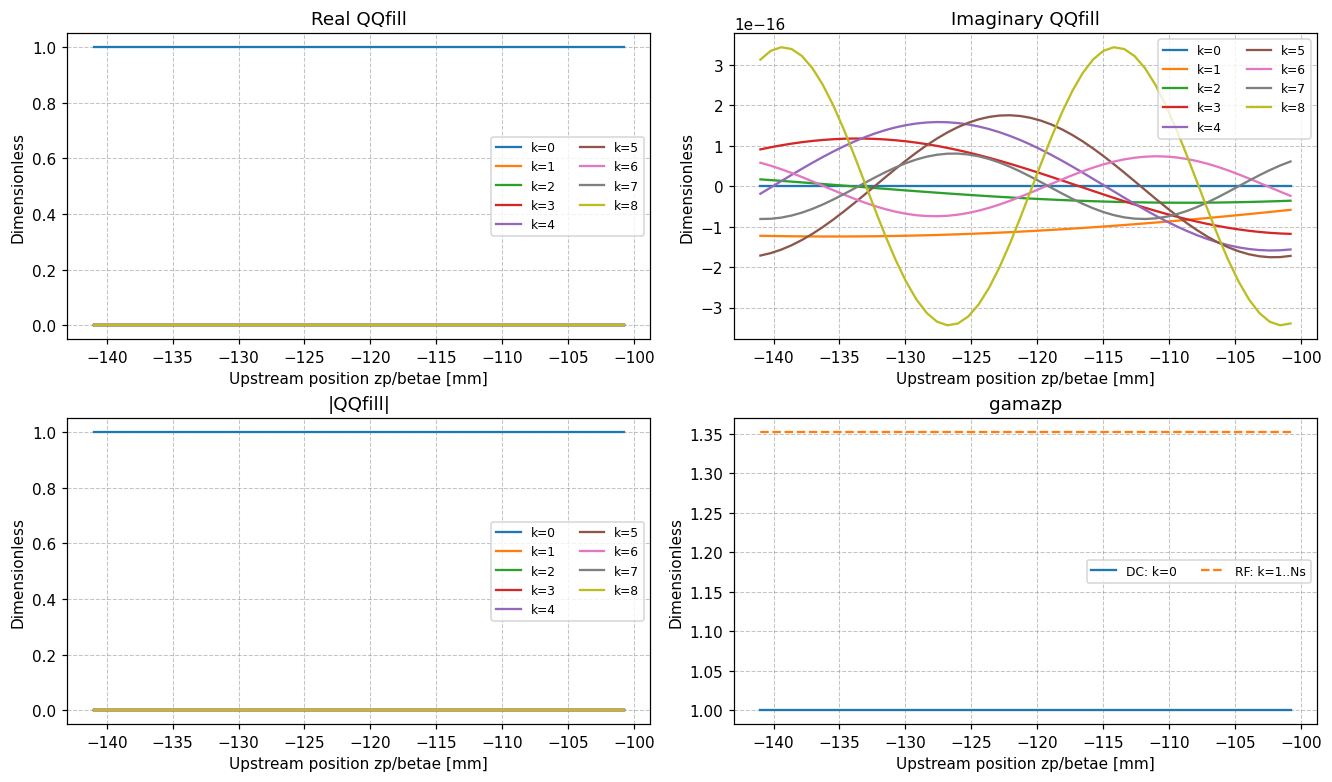

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7), layout="constrained")
if Nfill:
    for k in harmonics:
        axes[0, 0].plot(zp_mm, QQfill[:, k].real, label=f"k={k}")
        axes[0, 1].plot(zp_mm, QQfill[:, k].imag, label=f"k={k}")
        axes[1, 0].plot(zp_mm, np.abs(QQfill[:, k]), label=f"k={k}")
    axes[1, 1].plot(zp_mm, gamazp[:, 0], label="DC: k=0")
    axes[1, 1].plot(zp_mm, gamazp[:, 1], "--", label="RF: k=1..Ns")
    for ax in axes.flat:
        ax.legend(ncol=2, fontsize=8)
else:
    for ax in axes.flat:
        ax.text(0.5, 0.5, "No upstream sources (dN=0)", ha="center", transform=ax.transAxes)
for ax, title in zip(axes.flat, ("Real QQfill", "Imaginary QQfill", "|QQfill|", "gamazp")):
    ax.set(xlabel="Upstream position zp/betae [mm]", ylabel="Dimensionless", title=title)
plt.show()


## 6. Prefill field on the solver grid

The five cylindrical Bessel modes from the original MATLAB expression are summed at every target node. The source coordinates are normalized, so `abs(zp-z)/betae` restores a separation in mm before division by `rc`.

For the electron-beam convention used here, the upstream DC contribution is negative and approaches zero downstream. Uniform entrance current produces DC prefill; its RF terms are only roundoff. Use `case_name="modulated"` for nonzero RF terms.

The plots distinguish the whole device from the entrance region. No logarithmic floor or artificial nonzero value is introduced.


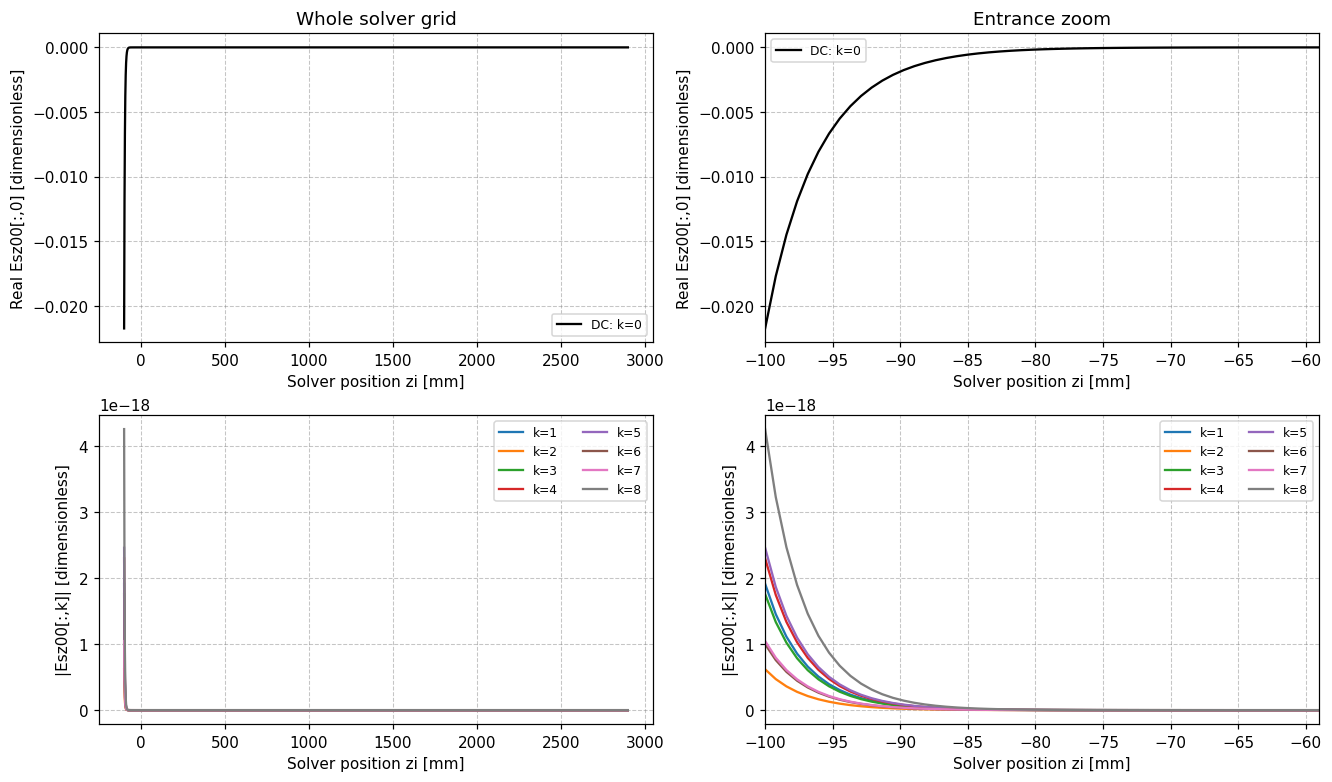

| Harmonic | Esz00 at entrance (complex) | Maximum magnitude |
|---|---|---|
| 0 | -0.021744845+0j | 2.174485e-02 |
| 1 | -1.6107626e-18+1.0303459e-18j | 1.912111e-18 |
| 2 | -2.0652305e-19+5.8310715e-19j | 6.185998e-19 |
| 3 | 5.3528446e-19+1.6726929e-18j | 1.756255e-18 |
| 4 | 2.9571746e-19+2.2785316e-18j | 2.297641e-18 |
| 5 | 4.2792053e-19+2.4198723e-18j | 2.457417e-18 |
| 6 | 9.9261796e-19-1.0751099e-19j | 9.984233e-19 |
| 7 | -9.7580554e-19-3.7730955e-19j | 1.046212e-18 |
| 8 | 1.5544477e-18+3.9601024e-18j | 4.254259e-18 |

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7), layout="constrained")
for column in range(2):
    axes[0, column].plot(grid.zi, Esz00[:, 0].real, color="black", label="DC: k=0")
    for k in range(1, Ns + 1):
        axes[1, column].plot(grid.zi, np.abs(Esz00[:, k]), label=f"k={k}")
    axes[0, column].set_ylabel("Real Esz00[:,0] [dimensionless]")
    axes[1, column].set_ylabel("|Esz00[:,k]| [dimensionless]")
    axes[0, column].set_title("Whole solver grid" if column == 0 else "Entrance zoom")
for ax in axes[:, 1]:
    ax.set_xlim(grid.zi[0], min(grid.zi[-1], grid.zi[0] + zoom_length))
for ax in axes.flat:
    ax.set_xlabel("Solver position zi [mm]")
    ax.legend(ncol=2, fontsize=8)
plt.show()

table = ["| Harmonic | Esz00 at entrance (complex) | Maximum magnitude |", "|---|---|---|"]
for k in harmonics:
    table.append(f"| {k} | {Esz00[0, k]:.8g} | {np.max(np.abs(Esz00[:, k])):.6e} |")
display(Markdown("\n".join(table)))


## 7. Complex RF field and reconstruction over one period

Select an RF harmonic `k` to inspect its real and imaginary parts. The lower plot reconstructs the prefill contribution at several solver nodes with the MATLAB convention

\[
E_{\mathrm{prefill}}(\theta)=\operatorname{Re}E_{0}
+\operatorname{Im}\sum_{k=1}^{Ns}E_k e^{ik\theta}.
\]

This is the **unweighted prefill contribution alone**, before the later `fillfactor/DCSPfactor` weighting and before adding in-domain space charge. It is not the total electric field.


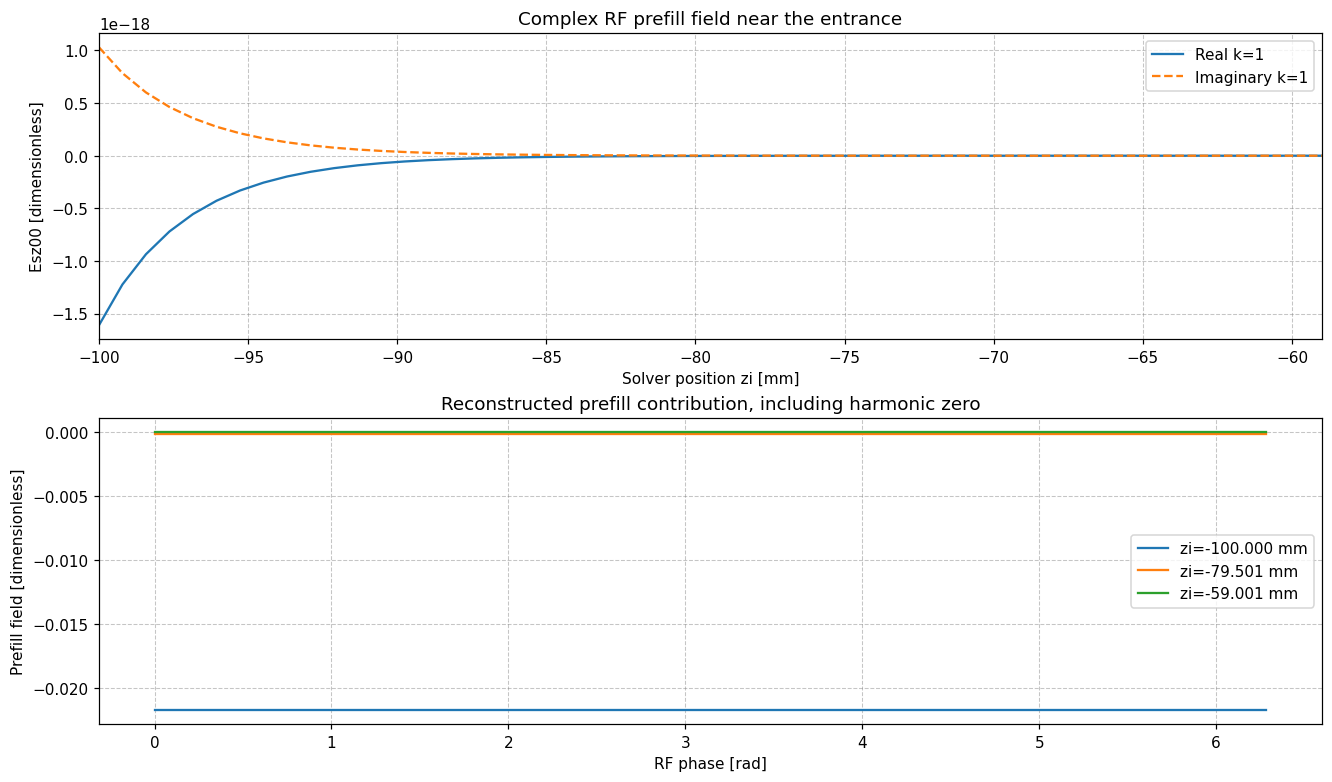

In [15]:
k = 1  # Physical RF harmonic; column zero is DC.
assert 1 <= k <= Ns
fig, axes = plt.subplots(2, 1, figsize=(12, 7), layout="constrained")
axes[0].plot(grid.zi, Esz00[:, k].real, label=f"Real k={k}")
axes[0].plot(grid.zi, Esz00[:, k].imag, "--", label=f"Imaginary k={k}")
axes[0].set(xlim=(grid.zi[0], min(grid.zi[-1], grid.zi[0] + zoom_length)),
            xlabel="Solver position zi [mm]", ylabel="Esz00 [dimensionless]",
            title="Complex RF prefill field near the entrance")
axes[0].legend()

theta = np.linspace(0.0, 2.0*np.pi, 500)
phase = np.exp(1.0j * np.outer(theta, np.arange(1, Ns + 1)))
z_indices = np.unique([0, min(Nfill // 2, len(grid.z)-1), min(Nfill, len(grid.z)-1)])
for kz in z_indices:
    waveform = Esz00[kz, 0].real + np.imag(phase @ Esz00[kz, 1:])
    axes[1].plot(theta, waveform, label=f"zi={grid.zi[kz]:.3f} mm")
axes[1].set(xlabel="RF phase [rad]", ylabel="Prefill field [dimensionless]",
            title="Reconstructed prefill contribution, including harmonic zero")
axes[1].legend()
plt.show()


## 8. Basic Python consistency checks

Check the source count, source ordering and spacing, DC/RF column layout, phase convention, kernel factors, and disabled/empty-grid behavior. The separate comparison notebook checks the independent MATLAB field values at every node and harmonic.


In [11]:
assert Nfill == grid.dN
assert zp.shape == gamazp.shape == QQfill.shape == (Nfill, Ns+1)
assert Esz00.shape == (len(grid.z), Ns+1)
assert np.isfinite(wp)
for values in (zp, gamazp, QQfill, Esz00):
    assert np.all(np.isfinite(values))

expected_zp = grid.z[0] - grid.dt * np.arange(1, Nfill+1)
np.testing.assert_allclose(zp, np.repeat(expected_zp[:, None], Ns+1, axis=1), rtol=1e-10, atol=1e-12)
np.testing.assert_allclose(gamazp[:, 0], 1.0, rtol=1e-10, atol=1e-12)
np.testing.assert_allclose(gamazp[:, 1:], beam_state.gamaz[0], rtol=1e-10, atol=1e-12)
np.testing.assert_allclose(QQfill[:, 0], beam_state.QQDC[0], rtol=1e-10, atol=1e-12)
expected_QQfill = beam_state.QQ[0] * np.exp(-1.0j * np.arange(1, Ns+1) * (grid.z[0] - zp[:, 1:]))
np.testing.assert_allclose(QQfill[:, 1:], expected_QQfill, rtol=1e-10, atol=1e-12)
if Nfill:
    np.testing.assert_allclose(zp_mm[0], grid.zi[0]-grid.dz, rtol=1e-10, atol=1e-12)
    np.testing.assert_allclose(np.diff(zp_mm), -grid.dz, rtol=1e-10, atol=1e-12)
    assert np.all(zp_mm < grid.zi[0])

np.testing.assert_allclose(Esz00[:, 0].imag, 0.0, rtol=0.0, atol=1e-12)
if not prefill_enabled or Nfill == 0:
    np.testing.assert_array_equal(Esz00, np.zeros_like(Esz00))
else:
    assert wp > 0 and Esz00[0, 0].real < 0
    assert np.all(Esz00[:, 0].real <= 1e-12)
    assert np.all(np.diff(Esz00[:, 0].real) >= -1e-12)

print("PASS: Python prefill geometry, phase, kernel and field checks.")
print("The Python–MATLAB comparison is a separate step.")


PASS: Python prefill geometry, phase, kernel and field checks.
The Python–MATLAB comparison is a separate step.


## 9. Export for the independent MATLAB test

This overwrites only `inputs.mat` and `python_results.mat` in this test folder.

Inputs contain raw beam/cavity/grid settings and the four space-charge controls, not Python-computed harmonics or fields. `Y0` is exported one-based and real integer inputs are saved as doubles.

Results contain 23 calculated quantities and six test settings (`Nt, Ns, factor, factorregion, fillfactor, DCSPfactor`), plus `case_name`. Complex matrices retain their dimensions; harmonic zero is a real column of `QQfill/Esz00`, not an additional entry in `QQ`. Source matrices retain shape `(0, Ns+1)` when `dN=0`.

Each folder stores one case. After any input change, rerun both implementations before comparing.


In [12]:
inputs = {
    **vars(beam),
    **vars(cavities),
    **vars(tube),
    **vars(numerical),
    "factorregion": factorregion,
    "factor": factor, "fillfactor": fillfactor, "DCSPfactor": DCSPfactor,
    "case_name": case_name,
    "c": c,
    "etom": etom,
    "mu01": mu01,
}
inputs["Y0"] = beam.Y0 + 1
for name, value in inputs.items():
    if np.asarray(value).dtype.kind in "iub":
        inputs[name] = np.asarray(value, dtype=float)

python_results = {
    **vars(reference),
    "w": grid.w, "betae": grid.betae, "dz": grid.dz, "zi": grid.zi,
    "z": grid.z, "dt": grid.dt, "dN": grid.dN,
    "QQDC": beam_state.QQDC, "QQ": beam_state.QQ, "gamaz": beam_state.gamaz,
    "wp": wp, "zp": zp, "gamazp": gamazp, "QQfill": QQfill, "Esz00": Esz00,
    "Nfill": Nfill, "case_name": case_name, "Nt": Nt, "Ns": Ns,
    "factor": factor, "factorregion": factorregion,
    "fillfactor": fillfactor, "DCSPfactor": DCSPfactor,
}
savemat(test_directory / "inputs.mat", inputs, oned_as="row")
savemat(test_directory / "python_results.mat", python_results, oned_as="row")

print("Saved:", test_directory / "inputs.mat")
print("Saved:", test_directory / "python_results.mat")
print("Next step: run spacecharge_prefill_test.mlx (or spacecharge_prefill_test.m) in MATLAB.")


Saved: C:\Users\lsito\Desktop\PyKlyC\pyKlyC\test\4.spacecharge_prefll_test\inputs.mat
Saved: C:\Users\lsito\Desktop\PyKlyC\pyKlyC\test\4.spacecharge_prefll_test\python_results.mat
Next step: run spacecharge_prefill_test.mlx (or spacecharge_prefill_test.m) in MATLAB.
